# Лабораторна робота №9. Моделювання і дослідження поведінки поширення соціальних процесів і систем

**Дисципліна:** Моделювання природничих, економічних та соціальних процесів  
**Спеціальність:** 113 «Прикладна математика», НН ФТІ, кафедра ММАД, КПІ ім. Ігоря Сікорського  
**Виконав:** Климентьєв Максим Андрійович

**Мета роботи:** дослідити детерміновані математичні моделі соціальних процесів на основі звичайних диференціальних рівнянь та стохастичні просторові моделі на основі клітинних автоматів методами обчислювального експерименту.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from labs.lab9.ca.relative_agreement import RelativeAgreementCA
from labs.lab9.ca.segregation import SchellingSegregationCA
from labs.lab9.ca.sznajd import SznajdCA
from labs.lab9.ca.voter import VoterModel
from labs.lab9.ode.population import (
    exponential_growth_continuous,
    exponential_growth_discrete,
    logistic_evolution,
)
from labs.lab9.ode.richardson import fit_wwi_historical_data, richardson_arms_race

plt.rcParams["figure.dpi"] = 120
print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Моделі зростання населення на основі диференціальних і різницевих рівнянь

### 1.1. Модель експоненціального зростання
За відсутності обмежень на ресурси приріст чисельності популяції пропорційний її поточному розміру:
* **дискретна форма:** $y_t - y_{t-1} = a y_{t-1} \implies y_t = (1 + a)y_{t-1}$, що утворює геометричну прогресію;
* **неперервна форма:** $\frac{dy}{dt} = ay \implies y(t) = y_0 e^{at}$, де $a$ — коефіцієнт приросту.

### 1.2. Модель логістичної еволюції Ферхюльста
У реальних системах зростання обмежується ємністю середовища $K$, а також смертністю з коефіцієнтом $m$ за інтенсивності народжуваності $r$:
$$\frac{dN}{dt} = rN(K - N) - mN.$$
За умови $rK > m$ система має нетривіальний стійкий стаціонарний стан:
$$N_c = K - \frac{m}{r},$$
до якого чисельність популяції прямує з будь-якого додатного початкового значення $N_0 > 0$.

=== Exponential Growth (y0 = 100, t = 20) ===
a = 0.05 | discrete y(20) =   265.33 | continuous y(20) =   271.83
a = 0.12 | discrete y(20) =   964.63 | continuous y(20) =  1102.32
a = 0.20 | discrete y(20) =  3833.76 | continuous y(20) =  5459.82

=== Logistic Evolution (r = 0.001, K = 1000, m = 0.2) ===
N0 =   50.0 | N(15) = 799.93 | theoretical Nc = 800.0
N0 =  400.0 | N(15) = 800.00 | theoretical Nc = 800.0
N0 = 1200.0 | N(15) = 800.00 | theoretical Nc = 800.0


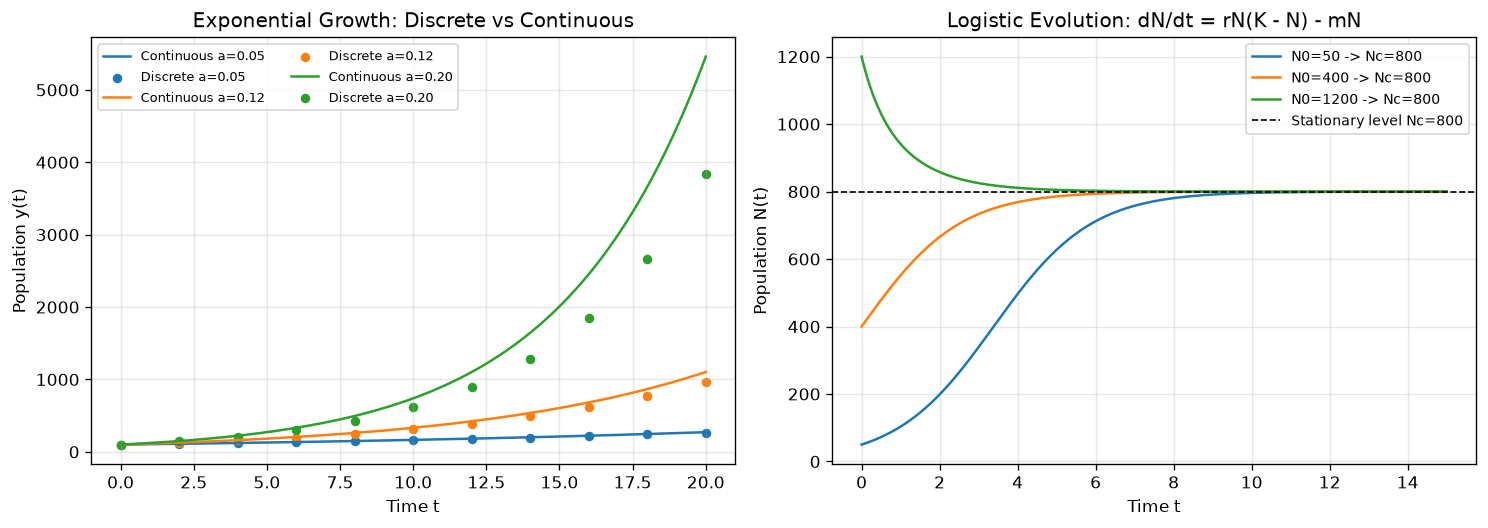

In [2]:
# Experiment 1: Exponential and Logistic Population Growth Models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.5))

rates = (0.05, 0.12, 0.20)
print("=== Exponential Growth (y0 = 100, t = 20) ===")
for rate in rates:
    y_disc = exponential_growth_discrete(y0=100.0, a=rate, steps=20)
    t_cont, y_cont = exponential_growth_continuous(y0=100.0, a=rate, dt=0.1, steps=200)
    line = ax1.plot(t_cont, y_cont, label=f"Continuous a={rate:.2f}")[0]
    ax1.scatter(
        range(0, 21, 2),
        y_disc[::2],
        color=line.get_color(),
        s=22,
        label=f"Discrete a={rate:.2f}",
    )
    print(
        f"a = {rate:.2f} | discrete y(20) = {y_disc[-1]:8.2f} | continuous y(20) = {y_cont[-1]:8.2f}"
    )

ax1.set_title("Exponential Growth: Discrete vs Continuous")
ax1.set_xlabel("Time t")
ax1.set_ylabel("Population y(t)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8, ncol=2)

print("\n=== Logistic Evolution (r = 0.001, K = 1000, m = 0.2) ===")
for n0 in (50.0, 400.0, 1200.0):
    t_log, n_log, eq = logistic_evolution(
        n0=n0, r=0.001, k=1000.0, m=0.2, dt=0.05, steps=300
    )
    ax2.plot(t_log, n_log, label=f"N0={n0:.0f} -> Nc={eq:.0f}")
    print(f"N0 = {n0:6.1f} | N(15) = {n_log[-1]:6.2f} | theoretical Nc = {eq:.1f}")

ax2.axhline(800.0, color="black", ls="--", lw=1.0, label="Stationary level Nc=800")
ax2.set_title("Logistic Evolution: dN/dt = rN(K - N) - mN")
ax2.set_xlabel("Time t")
ax2.set_ylabel("Population N(t)")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()

**Висновки до розділу 1:**
1. На малому інтервалі часу та при малих коефіцієнтах приросту $a$ дискретна та неперервна експоненційні криві близькі, проте з ростом $a$ неперервна модель зростає швидше за рахунок безперервного нарахування приросту: $e^a > 1 + a$ для всіх $a > 0$.
2. У логістичній моделі розв'язок наближається до єдиного стаціонарного рівня $N_c = 1000 - \frac{0.2}{0.001} = 800$ як знизу при $N_0 = 50$ і $N_0 = 400$, так і зверху при $N_0 = 1200$, що підтверджує асимптотичну стійкість точки рівноваги.

## 2. Модель гонки озброєнь Річардсона

Динаміка військових витрат $x(t)$ і $y(t)$ двох протиборчих сторін описується системою лінійних диференціальних рівнянь:
$$\begin{cases} \dfrac{dx}{dt} = ay - mx + r, \\[6pt] \dfrac{dy}{dt} = bx - ny + s, \end{cases}$$
де $a, b > 0$ — коефіцієнти реагування на озброєння опонента, $m, n > 0$ — коефіцієнти економічного стримування витрат, а $r, s$ — сталі претензій при додатних значеннях або доброї волі при від'ємних значеннях.

Координати точки рівноваги при $\Delta = mn - ab \neq 0$:
$$X^* = \frac{as + rn}{mn - ab}, \qquad Y^* = \frac{br + sm}{mn - ab}.$$
Поведінка системи визначається знаком визначника $\Delta = mn - ab$ та знаками констант $r, s$:
1. $\Delta > 0, r > 0, s > 0$ — існує стійка точка рівноваги в першому квадранті;
2. $\Delta < 0, r > 0, s > 0$ — нестійкість і необмежена ескалація гонки озброєнь;
3. $\Delta > 0, r < 0, s < 0$ — стійке взаємне роззброєння до нульового рівня;
4. $\Delta < 0, r < 0, s < 0$ — сідловий режим, у якому траєкторія прямує або до роззброєння, або до ескалації залежно від початкового стану $(x_0, y_0)$.

Для перевірки моделі на історичних даних 1909–1913 рр. припускається симетрія $a = b$, $m = n$, що зводить систему до одного рівняння для сумарних витрат $z = x + y$:
$$\frac{dz}{dt} = kz + f, \quad k = a - m, \quad f = r + s.$$

=== Richardson Model Stability Regimes ===
Case 1: Stable balance    | det=+0.4950 | stable=True  | eq=(29.09, 29.49)     | final=(29.0, 29.5)
Case 2: Escalation        | det=-0.4050 | stable=False | eq=None in R+^2       | final=(133.7, 126.7)
Case 3: Disarmament       | det=+0.5000 | stable=True  | eq=None in R+^2       | final=(0.0, 0.0)
Case 4a: Saddle disarm    | det=-0.3600 | stable=False | eq=(45.00, 43.33)     | final=(0.0, 0.0)
Case 4b: Saddle escalate  | det=-0.3600 | stable=False | eq=(45.00, 43.33)     | final=(105.8, 100.7)

WWI 1909-1913 linear regression: k = 0.7468, f = -145.62


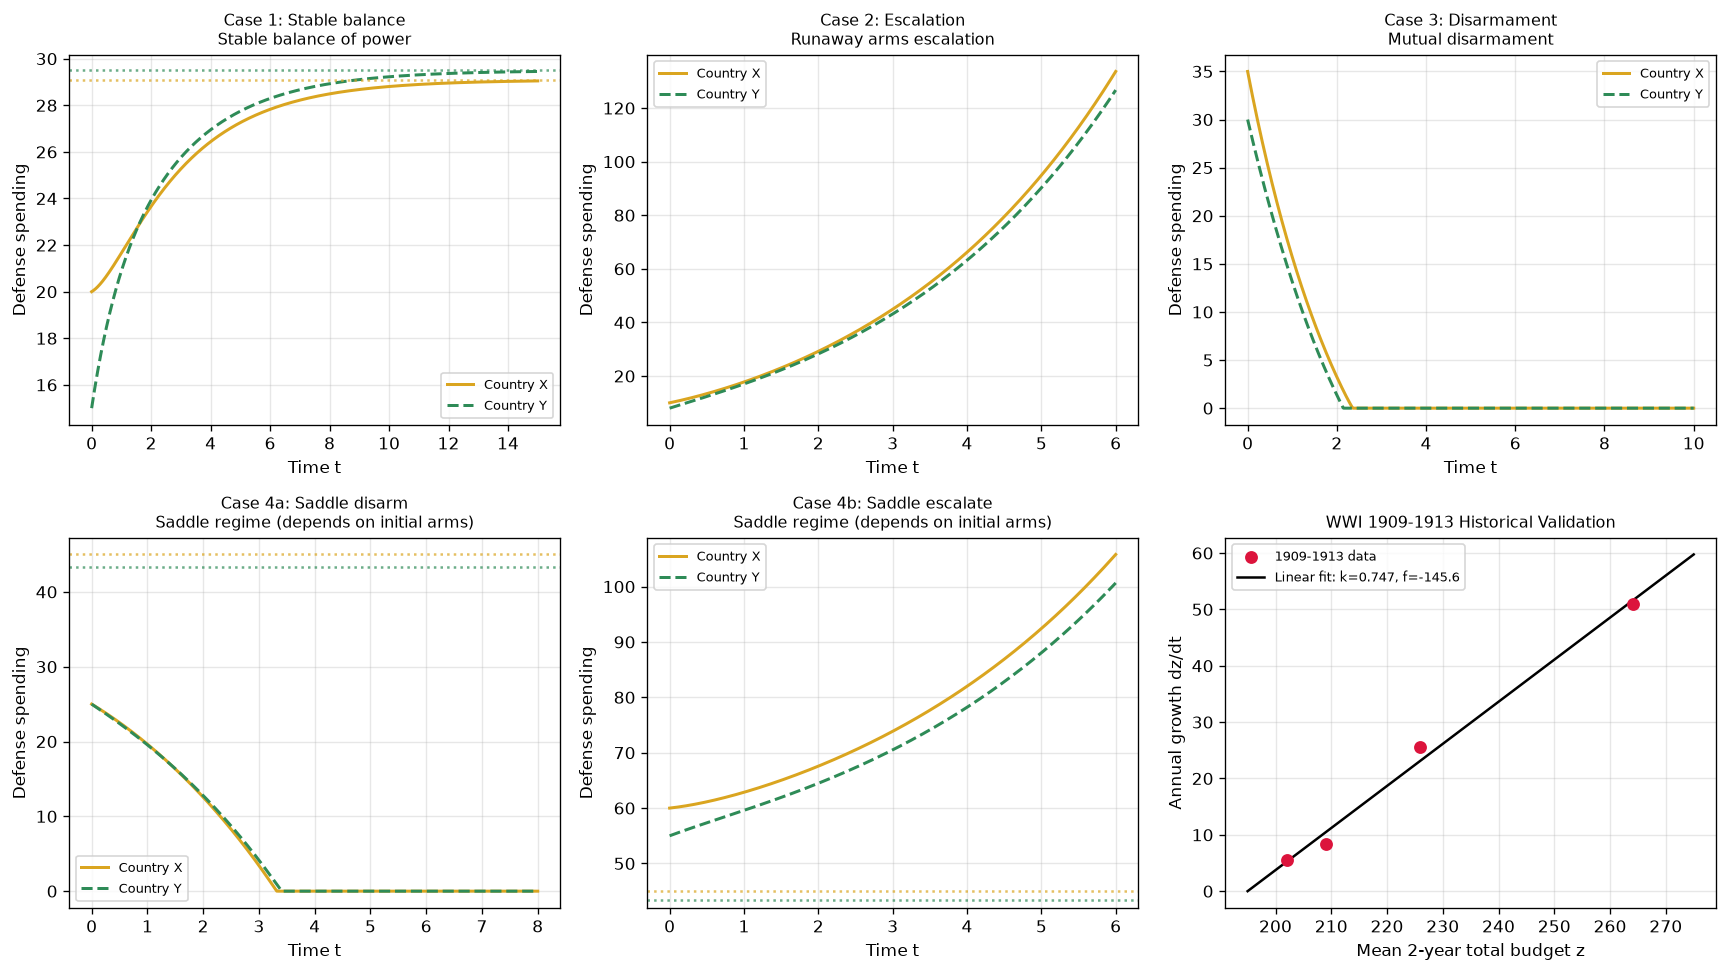

In [3]:
# Experiment 2: Stability Regimes of Richardson Arms Race Model & WWI Historical Fit
cases = [
    ("Case 1: Stable balance", (20.0, 15.0, 0.45, 0.80, 10.0, 0.50, 0.90, 12.0, 1500)),
    ("Case 2: Escalation", (10.0, 8.0, 0.85, 0.50, 4.0, 0.80, 0.55, 5.0, 600)),
    ("Case 3: Disarmament", (35.0, 30.0, 0.40, 0.80, -8.0, 0.45, 0.85, -10.0, 1000)),
    ("Case 4a: Saddle disarm", (25.0, 25.0, 0.90, 0.60, -12.0, 0.80, 0.60, -10.0, 800)),
    (
        "Case 4b: Saddle escalate",
        (60.0, 55.0, 0.90, 0.60, -12.0, 0.80, 0.60, -10.0, 600),
    ),
]

fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.2))
ax_list = axes.ravel()

print("=== Richardson Model Stability Regimes ===")
for idx, (label, params) in enumerate(cases):
    x0, y0, a, m, r, b, n, s, steps = params
    det = m * n - a * b
    t_vals, x_vals, y_vals, eq, is_stable, regime = richardson_arms_race(
        x0, y0, a, m, r, b, n, s, dt=0.01, steps=steps
    )
    ax = ax_list[idx]
    ax.plot(t_vals, x_vals, label="Country X", color="goldenrod", lw=1.8)
    ax.plot(t_vals, y_vals, label="Country Y", color="seagreen", ls="--", lw=1.8)
    if eq is not None:
        ax.axhline(eq[0], color="goldenrod", ls=":", alpha=0.7)
        ax.axhline(eq[1], color="seagreen", ls=":", alpha=0.7)
    ax.set_title(f"{label}\n{regime}", fontsize=9.5)
    ax.set_xlabel("Time t")
    ax.set_ylabel("Defense spending")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

    eq_str = f"({eq[0]:.2f}, {eq[1]:.2f})" if eq is not None else "None in R+^2"
    print(
        f"{label:25s} | det={det:+.4f} | stable={str(is_stable):5s} | "
        f"eq={eq_str:18s} | final=({x_vals[-1]:.1f}, {y_vals[-1]:.1f})"
    )

wwi = fit_wwi_historical_data()
ax_wwi = ax_list[5]
ax_wwi.scatter(
    wwi["mean_z"],
    wwi["growth_dz"],
    color="crimson",
    s=45,
    zorder=3,
    label="1909-1913 data",
)
z_grid = np.linspace(195.0, 275.0, 50)
ax_wwi.plot(
    z_grid,
    wwi["k"] * z_grid + wwi["f"],
    color="black",
    lw=1.5,
    label=f"Linear fit: k={wwi['k']:.3f}, f={wwi['f']:.1f}",
)
ax_wwi.set_title("WWI 1909-1913 Historical Validation", fontsize=9.5)
ax_wwi.set_xlabel("Mean 2-year total budget z")
ax_wwi.set_ylabel("Annual growth dz/dt")
ax_wwi.grid(True, alpha=0.3)
ax_wwi.legend(fontsize=8)

print(f"\nWWI 1909-1913 linear regression: k = {wwi['k']:.4f}, f = {wwi['f']:.2f}")

plt.tight_layout()
plt.show()

**Висновки до розділу 2:**
1. У першому режимі економічне стримування переважає взаємну реакцію на озброєння ($mn - ab = 0.495 > 0$), тому витрати сторін стабілізуються біля рівноважної пари $(X^*, Y^*) = (29.09, 29.49)$.
2. У сідловому режимі ($mn - ab = -0.36 < 0$, $r < 0, s < 0$) одна й та сама система параметрів дає протилежні результати: при низьких початкових витратах $(25, 25)$ система переходить у повне роззброєння, а при високих $(60, 55)$ — у неконтрольовану ескалацію.
3. Апроксимація сумарних військових бюджетів Франції, Російської імперії, Німеччини та Австро-Угорщини за 1909–1913 рр. дає додатний нахил $k = a - m \approx 0.747 > 0$, що свідчить про нестійку експоненційну ескалацію напередодні Першої світової війни.

## 3. Клітинно-автоматні моделі формування громадської думки

### 3.1. Модель виборця (The Voter Model)
У вузлах регулярної решітки розміщуються виборці зі станами $+1$ або $-1$. На кожній ітерації випадково обирається один вузол і приймає думку випадкового сусіда з околу Мура доти, доки вся решітка не досягне одностайного консенсусу.
Теоретично ймовірність досягнення консенсусу $+1$ дорівнює початковій частці прихильників $P(+1) = \rho$, а середній час досягнення консенсусу масштабується як $O(N^2)$ для одновимірної решітки та $O(N \ln N)$ для двовимірної решітки з кількістю вузлів $N$.

=== Voter Model on 10x10 Grid (20 trials per rho) ===
rho = 0.65 | empirical P(+1) = 0.75 | mean steps =   7815.6
rho = 0.70 | empirical P(+1) = 0.75 | mean steps =   7742.4
rho = 0.75 | empirical P(+1) = 0.75 | mean steps =   7587.4
rho = 0.80 | empirical P(+1) = 0.75 | mean steps =   7256.1
rho = 0.85 | empirical P(+1) = 0.80 | mean steps =   6342.4
rho = 0.90 | empirical P(+1) = 0.90 | mean steps =   4731.1
rho = 0.95 | empirical P(+1) = 0.90 | mean steps =   3600.1

=== Voter Model: 1D vs 2D Scaling (rho = 0.75, 20 trials) ===
1D N=20            | mean steps =    1001.6
1D N=40            | mean steps =    5889.9
2D 10x10 (N=100)   | mean steps =    8053.5
2D 20x20 (N=400)   | mean steps =  139164.0


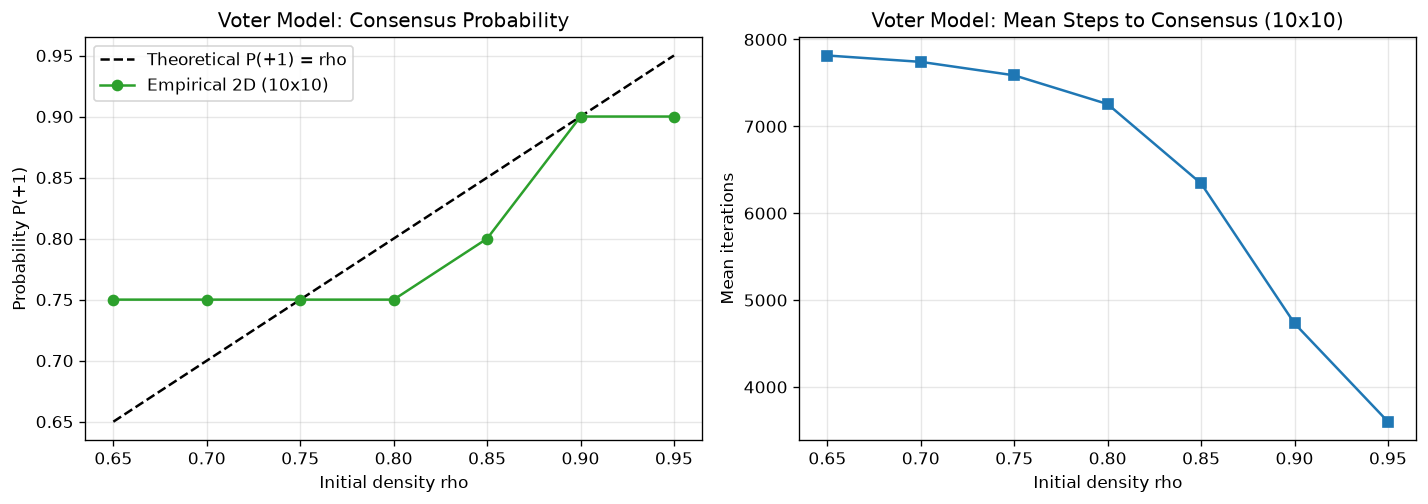

In [4]:
# Experiment 3.1: Voter Model Consensus Probability and Dimensional Scaling
rhos = [0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
trials = 20
win_probs: list[float] = []
mean_steps: list[float] = []

print("=== Voter Model on 10x10 Grid (20 trials per rho) ===")
for rho in rhos:
    wins = 0
    steps_list: list[int] = []
    for trial in range(trials):
        model = VoterModel(shape=(10, 10), rho=rho, seed=1000 + trial)
        winner, steps = model.run_until_consensus()
        if winner == 1:
            wins += 1
        steps_list.append(steps)
    prob = wins / trials
    avg_s = float(np.mean(steps_list))
    win_probs.append(prob)
    mean_steps.append(avg_s)
    print(f"rho = {rho:.2f} | empirical P(+1) = {prob:.2f} | mean steps = {avg_s:8.1f}")

print("\n=== Voter Model: 1D vs 2D Scaling (rho = 0.75, 20 trials) ===")
scaling_configs = [
    ("1D N=20", (20,)),
    ("1D N=40", (40,)),
    ("2D 10x10 (N=100)", (10, 10)),
    ("2D 20x20 (N=400)", (20, 20)),
]
for label, grid_shape in scaling_configs:
    steps_list = []
    for trial in range(trials):
        model = VoterModel(shape=grid_shape, rho=0.75, seed=3000 + trial)
        _, steps = model.run_until_consensus(max_steps=1_000_000)
        steps_list.append(steps)
    print(f"{label:18s} | mean steps = {np.mean(steps_list):9.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.plot(rhos, rhos, "k--", label="Theoretical P(+1) = rho")
ax1.plot(rhos, win_probs, "o-", color="tab:green", label="Empirical 2D (10x10)")
ax1.set_title("Voter Model: Consensus Probability")
ax1.set_xlabel("Initial density rho")
ax1.set_ylabel("Probability P(+1)")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(rhos, mean_steps, "s-", color="tab:blue")
ax2.set_title("Voter Model: Mean Steps to Consensus (10x10)")
ax2.set_xlabel("Initial density rho")
ax2.set_ylabel("Mean iterations")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.2. Модель взаємодії (The Relative Agreement Interaction Model)
Кожен індивід на решітці $50 \times 50$ ($N = 2500$ агентів) отримує початкову думку $O_i \in [1, 256]$. На кожному кроці випадково обирається агент і його сусід. Якщо різниця їхніх поглядів менша за поріг довіри $|O_i - O_j| < e$, їхні думки зближуються на величину $\frac{m}{2}(O_i - O_j)$, де $m$ — коефіцієнт впливу. Якщо різниця перевищує $e$, взаємодія не відбувається.

=== Relative Agreement Model (50x50 = 2500 agents, 200,000 steps) ===
e =  10.0, m = 0.3 | clusters =  1 | mean opinion shift =   1.48
e =  50.0, m = 0.3 | clusters =  3 | mean opinion shift =  24.83
e = 100.0, m = 0.3 | clusters = 12 | mean opinion shift =  62.68
e =  10.0, m = 0.6 | clusters =  1 | mean opinion shift =   1.50
e =  50.0, m = 0.6 | clusters =  5 | mean opinion shift =  26.89
e = 100.0, m = 0.6 | clusters = 14 | mean opinion shift =  62.11


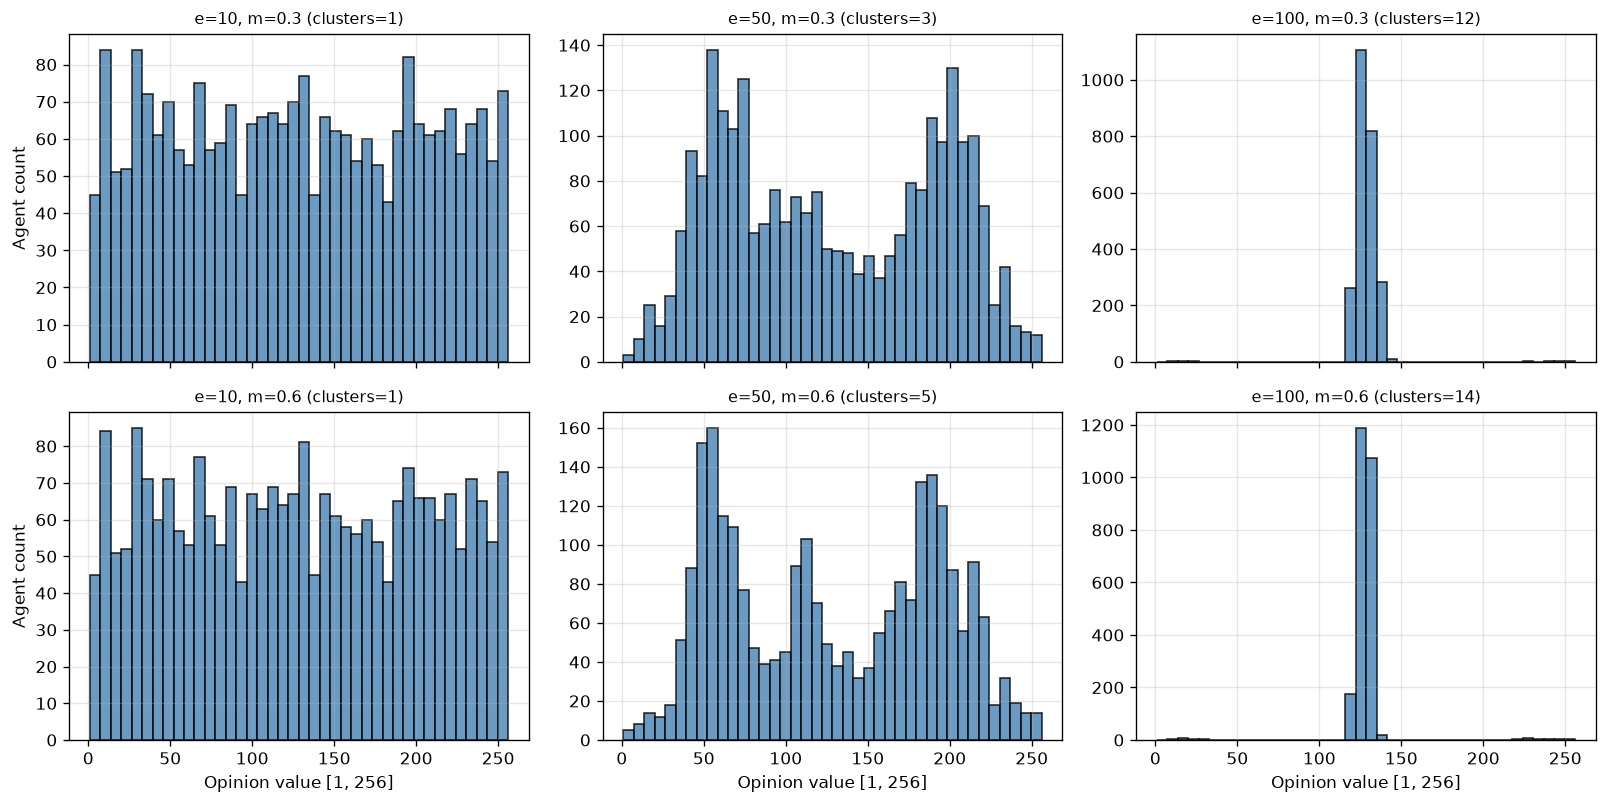

In [5]:
# Experiment 3.2: Relative Agreement Model on 50x50 Grid
e_values = (10.0, 50.0, 100.0)
m_values = (0.3, 0.6)

fig, axes = plt.subplots(len(m_values), len(e_values), figsize=(13.5, 6.8), sharex=True)

print("=== Relative Agreement Model (50x50 = 2500 agents, 200,000 steps) ===")
for row_idx, m_val in enumerate(m_values):
    for col_idx, e_val in enumerate(e_values):
        ra = RelativeAgreementCA(
            shape=(50, 50), e_threshold=e_val, m_influence=m_val, seed=42
        )
        for _ in range(200_000):
            ra.step()
        clusters = ra.count_clusters()
        shift = ra.mean_opinion_shift()
        print(
            f"e = {e_val:5.1f}, m = {m_val:.1f} | clusters = {clusters:2d} | "
            f"mean opinion shift = {shift:6.2f}"
        )

        ax = axes[row_idx, col_idx]
        ax.hist(
            ra.grid.ravel(),
            bins=40,
            range=(1, 256),
            color="steelblue",
            edgecolor="black",
            alpha=0.8,
        )
        ax.set_title(
            f"e={e_val:.0f}, m={m_val:.1f} (clusters={clusters})", fontsize=9.5
        )
        ax.grid(True, alpha=0.3)
        if row_idx == len(m_values) - 1:
            ax.set_xlabel("Opinion value [1, 256]")
        if col_idx == 0:
            ax.set_ylabel("Agent count")

plt.tight_layout()
plt.show()

### 3.3. Модель Шнайда (The Sznajd Model)
Модель формалізує принцип соціального підтвердження «разом ми стоїмо, розділившись падаємо». На решітці $50 \times 50$ з періодичними граничними умовами на кожній ітерації випадково обирається індивід та один із його сусідів. Якщо їхні погляди збігаються, усі сусіди цієї пари приймають їхню думку. Досліджується швидкість виходу на консенсус при початковій перевазі однієї думки на $1\%$, $5\%$ та $10\%$.

=== Sznajd Model (50x50 periodic grid, 10 trials per advantage) ===
Advantage    1% | majority win rate =  40.0% | mean steps =  136101.6
Advantage    5% | majority win rate =  70.0% | mean steps =  118526.7
Advantage   10% | majority win rate =  90.0% | mean steps =   90370.1


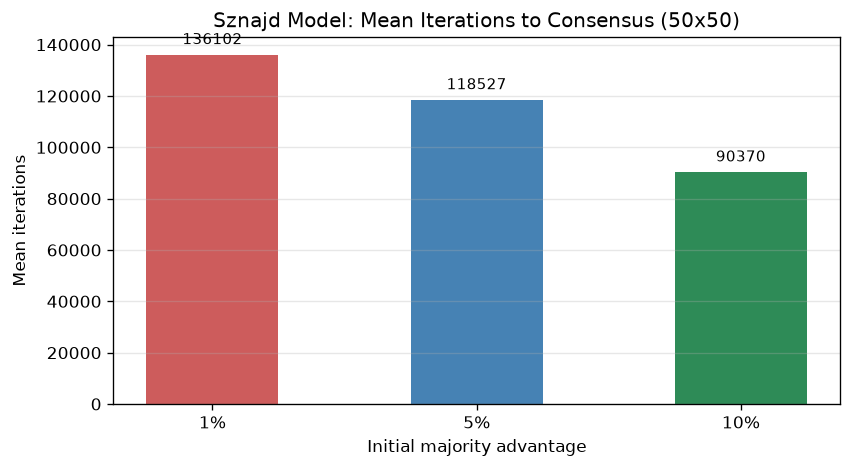

In [6]:
# Experiment 3.3: Sznajd Model on 50x50 Periodic Grid
advantages = (0.01, 0.05, 0.10)
sznajd_trials = 10
sznajd_mean_steps: list[float] = []
sznajd_win_rates: list[float] = []

print("=== Sznajd Model (50x50 periodic grid, 10 trials per advantage) ===")
for adv in advantages:
    wins = 0
    steps_list: list[int] = []
    for trial in range(sznajd_trials):
        sz = SznajdCA(shape=(50, 50), advantage=adv, seed=2000 + trial)
        winner, steps = sz.run_until_consensus(max_steps=2_000_000)
        if winner == 1:
            wins += 1
        steps_list.append(steps)
    mean_s = float(np.mean(steps_list))
    win_pct = (wins / sznajd_trials) * 100.0
    sznajd_mean_steps.append(mean_s)
    sznajd_win_rates.append(win_pct)
    print(
        f"Advantage {adv * 100:4.0f}% | majority win rate = {win_pct:5.1f}% | "
        f"mean steps = {mean_s:9.1f}"
    )

fig, ax = plt.subplots(figsize=(7.2, 4.0))
labels = ["1%", "5%", "10%"]
bars = ax.bar(
    labels, sznajd_mean_steps, color=["indianred", "steelblue", "seagreen"], width=0.5
)
ax.set_title("Sznajd Model: Mean Iterations to Consensus (50x50)")
ax.set_xlabel("Initial majority advantage")
ax.set_ylabel("Mean iterations")
ax.grid(True, axis="y", alpha=0.3)

for bar, val in zip(bars, sznajd_mean_steps):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        val + max(sznajd_mean_steps) * 0.02,
        f"{val:.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

**Висновки до розділу 3:**
1. У моделі виборця ймовірність перемоги думки $+1$ відповідає її початковій частці $\rho$, а час досягнення консенсусу зростає при наближенні $\rho$ до $0.5$. Порівняння 1D і 2D підтверджує швидше зростання кількості кроків відносно числа вузлів в одновимірному випадку через вузький фронт взаємодії між сусідами.
2. У моделі взаємодії за вузького порогу довіри $e = 10$ агенти взаємодіють лише з найближчими за поглядами сусідами, тому розподіл залишається майже рівномірним із середнім зсувом $\approx 1.5$. При $e = 50$ формуються два виражені поляризовані табори біля значень $60$ і $195$, а при $e = 100$ майже вся популяція збирається в один центральний пік біля середини шкали з поодинокими крайніми «екстремістами». Збільшення $m$ з $0.3$ до $0.6$ прискорює стягування думок до центрів груп.
3. У моделі Шнайда парний соціальний тиск забезпечує досягнення консенсусу, а збільшення початкової переваги з $1\%$ до $5\%$ і $10\%$ скорочує середню кількість ітерацій зі $136\,102$ до $90\,370$ і підвищує частку перемог початкової більшості з $40\%$ до $90\%$.

## 4. Модель процесу расової сегрегації Шеллінга

На решітці $50 \times 50$ кожна клітинка відповідає будинку, який може бути порожнім або зайнятим однією з двох груп населення. Частка порожніх будинків становить $28\%$. На кожному такті перевіряється задоволеність кожної родини в околі Мура за двома правилами толерантності:
1. не менше $1/2$ сусідніх зайнятих будинків належать тій самій групі;
2. не менше $1/3$ сусідніх зайнятих будинків належать тій самій групі.

Незадоволена родина переїжджає в найближчий порожній будинок, де її вимога до складу сусідів виконується.

=== Schelling Segregation Model (50x50 grid, 28% empty cells) ===
Rule 1: >= 1/2 same group   | sweeps =  7 | segregation index: 0.500 -> 0.786
Rule 2: >= 1/3 same group   | sweeps =  5 | segregation index: 0.500 -> 0.644


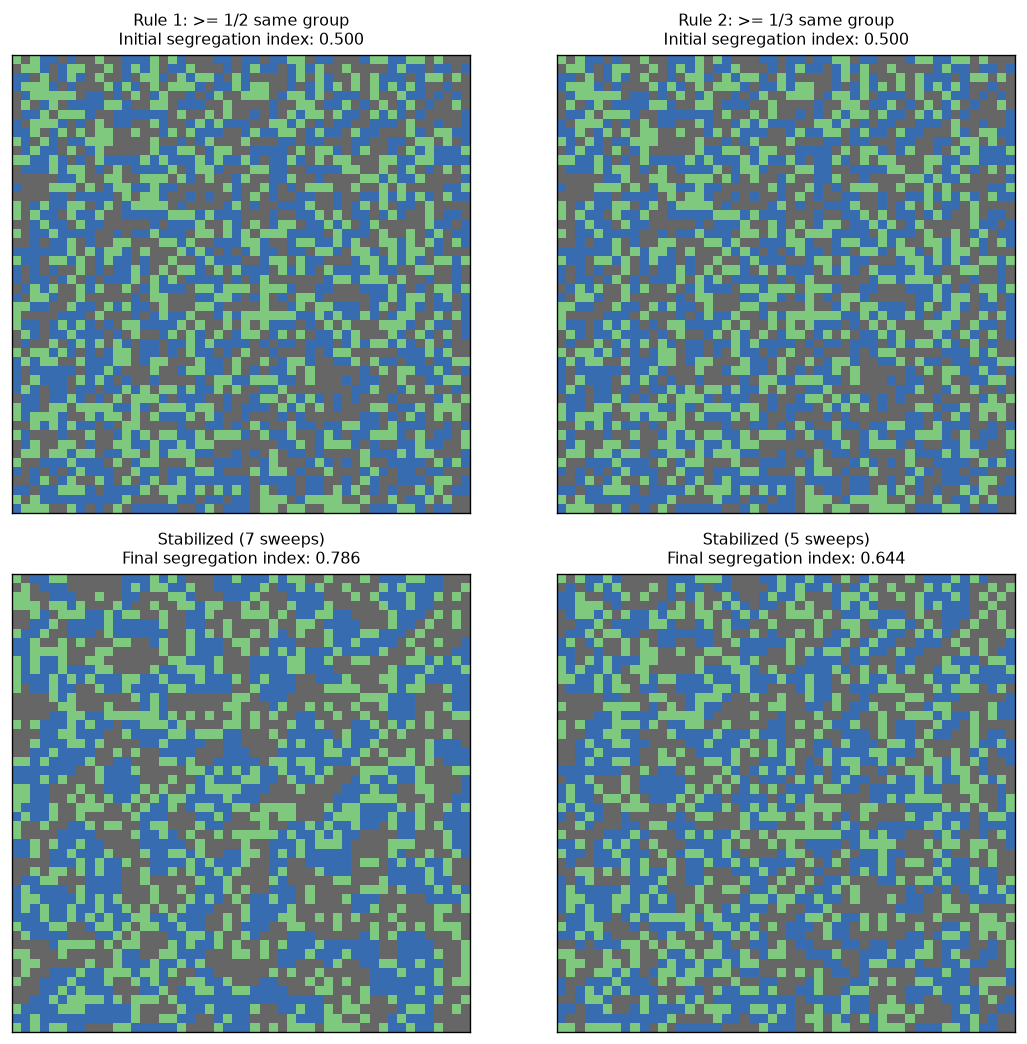

In [7]:
# Experiment 4: Schelling Segregation Model under 1/2 and 1/3 Tolerance Rules
thresholds = [
    (0.5, "Rule 1: >= 1/2 same group"),
    (1.0 / 3.0, "Rule 2: >= 1/3 same group"),
]

fig, axes = plt.subplots(2, 2, figsize=(9.5, 8.8))

print("=== Schelling Segregation Model (50x50 grid, 28% empty cells) ===")
for idx, (tau, title) in enumerate(thresholds):
    model = SchellingSegregationCA(
        shape=(50, 50), empty_ratio=0.28, similarity_threshold=tau, seed=42
    )
    init_idx = model.segregation_index()
    axes[0, idx].imshow(
        model.grid, cmap="Accent", vmin=0, vmax=2, interpolation="nearest"
    )
    axes[0, idx].set_title(
        f"{title}\nInitial segregation index: {init_idx:.3f}", fontsize=9.5
    )
    axes[0, idx].set_xticks([])
    axes[0, idx].set_yticks([])

    sweeps = 0
    for step in range(1, 101):
        sweeps = step
        if model.step() == 0:
            break

    final_idx = model.segregation_index()
    axes[1, idx].imshow(
        model.grid, cmap="Accent", vmin=0, vmax=2, interpolation="nearest"
    )
    axes[1, idx].set_title(
        f"Stabilized ({sweeps} sweeps)\nFinal segregation index: {final_idx:.3f}",
        fontsize=9.5,
    )
    axes[1, idx].set_xticks([])
    axes[1, idx].set_yticks([])

    print(
        f"{title:27s} | sweeps = {sweeps:2d} | "
        f"segregation index: {init_idx:.3f} -> {final_idx:.3f}"
    )

plt.tight_layout()
plt.show()

## Загальні висновки

У ході лабораторної роботи було програмно реалізовано та досліджено два класи математичних моделей соціальних процесів:
1. **Детерміновані моделі на основі диференціальних рівнянь** описують макроскопічну динаміку системи через агреговані змінні. Модель Ферхюльста демонструє перехід від експоненціального зростання до насичення на рівні $N_c = K - m/r$, а модель Річардсона дозволяє аналітично визначити межу між стійким балансом сил, взаємним роззброєнням і некерованою ескалацією гонки озброєнь.
2. **Стохастичні клітинно-автоматні моделі** відтворюють колективні явища через локальні правила взаємодії агентів на решітці. Моделі виборця та Шнайда показують механізм формування єдиного консенсусу під дією локального або парного соціального впливу, модель відносної згоди пояснює поляризацію та утворення закритих кластерів при обмеженій довірі, а модель Шеллінга доводить, що навіть слабкі індивідуальні переваги до складу найближчого оточення спричиняють виражену просторову сегрегацію.